# CineMatch - Week 1: Data Preparation
This notebook loads MovieLens Small, validates and merges its tables, examines rating behavior and the popularity long tail, builds the user-item utility matrix, and measures sparsity. All displayed values are computed from the local CSV files.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))

from cinematch.data import calculate_sparsity, load_movielens, make_utility_matrix
from cinematch.week1 import build_summary, run_week1

ModuleNotFoundError: No module named 'surprise'

## 1. Load, validate, and merge the data

In [ ]:
ratings, movies, merged = load_movielens(ROOT / 'data' / 'raw')
print(f'{len(ratings):,} ratings | {ratings.userId.nunique():,} users | {len(movies):,} catalog movies')
merged.head()

100,836 ratings | 610 users | 9,742 catalog movies


,userId,movieId,rating,timestamp,title,genres
0,1,1,4.0,964982703,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,1,3,4.0,964981247,Grumpier Old Men (1995),Comedy|Romance
2,1,6,4.0,964982224,Heat (1995),Action|Crime|Thriller
3,1,47,5.0,964983815,Seven (a.k.a. Se7en) (1995),Mystery|Thriller
4,1,50,5.0,964982931,"Usual Suspects, The (1995)",Crime|Mystery|Thriller


## 2. Build the user-item utility matrix and calculate sparsity

In [ ]:
utility = make_utility_matrix(ratings)
sparsity = calculate_sparsity(utility)
print(f'Utility matrix shape: {utility.shape}')
print(f'Observed ratings: {utility.notna().sum().sum():,} of {utility.size:,} cells')
print(f'Sparsity: {sparsity:.4%}')
utility.iloc[:5, :10]

NameError: name 'ratings' is not defined

## 3. Generate and inspect the Week 1 artifacts

In [ ]:
summary = run_week1(ROOT)
pd.Series({k: v for k, v in summary.items() if not isinstance(v, (dict, list))}, name='value')

NameError: name 'run_week1' is not defined

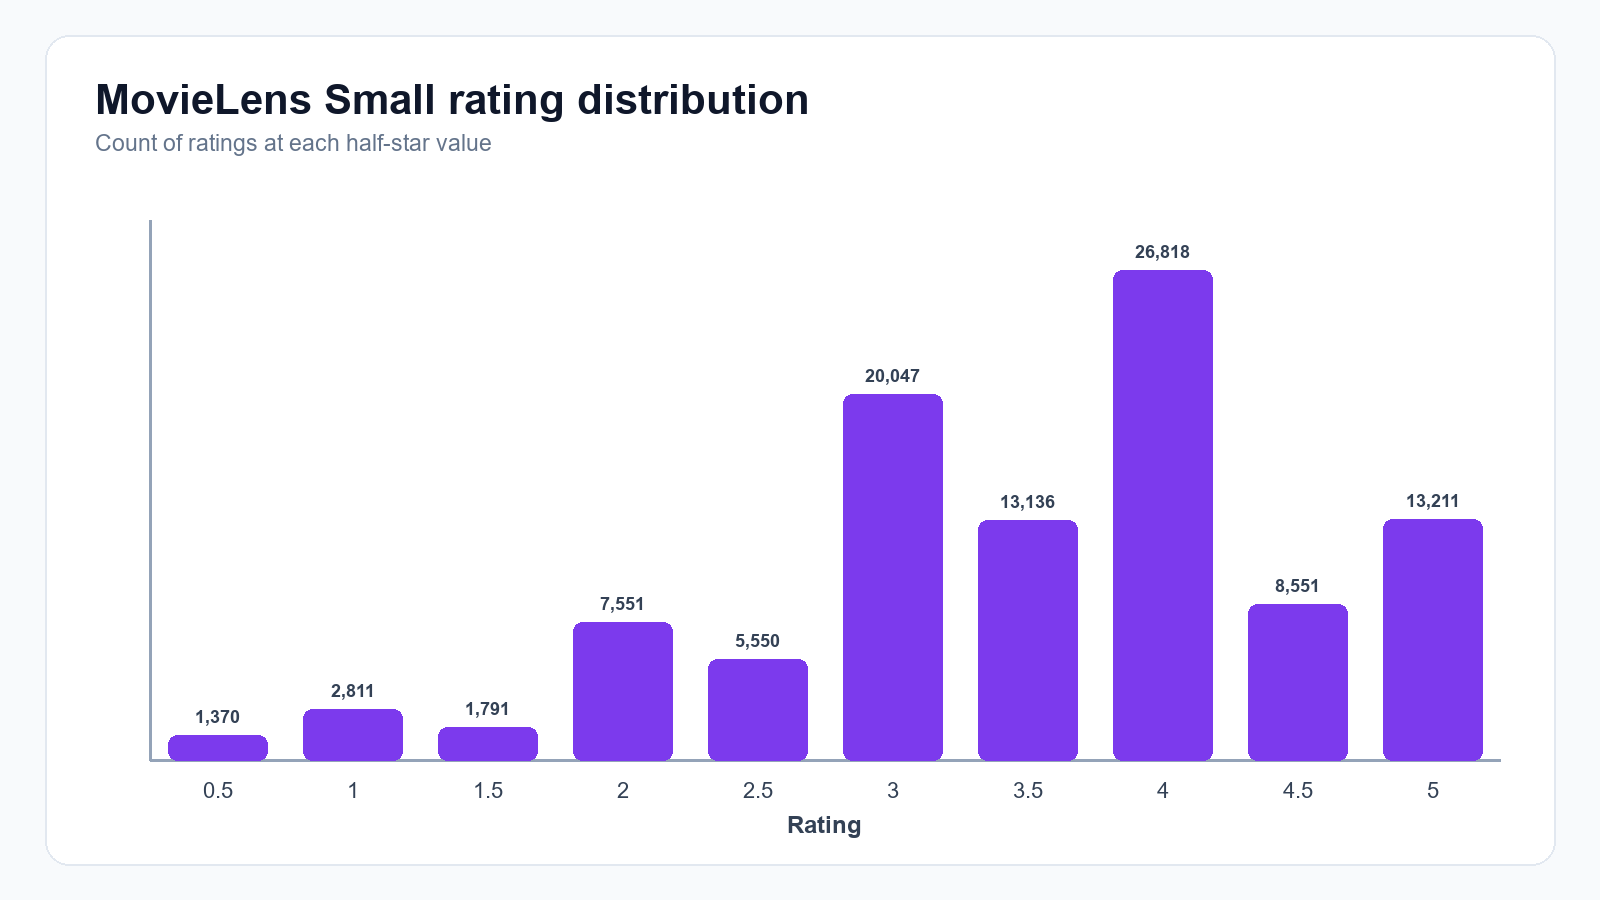

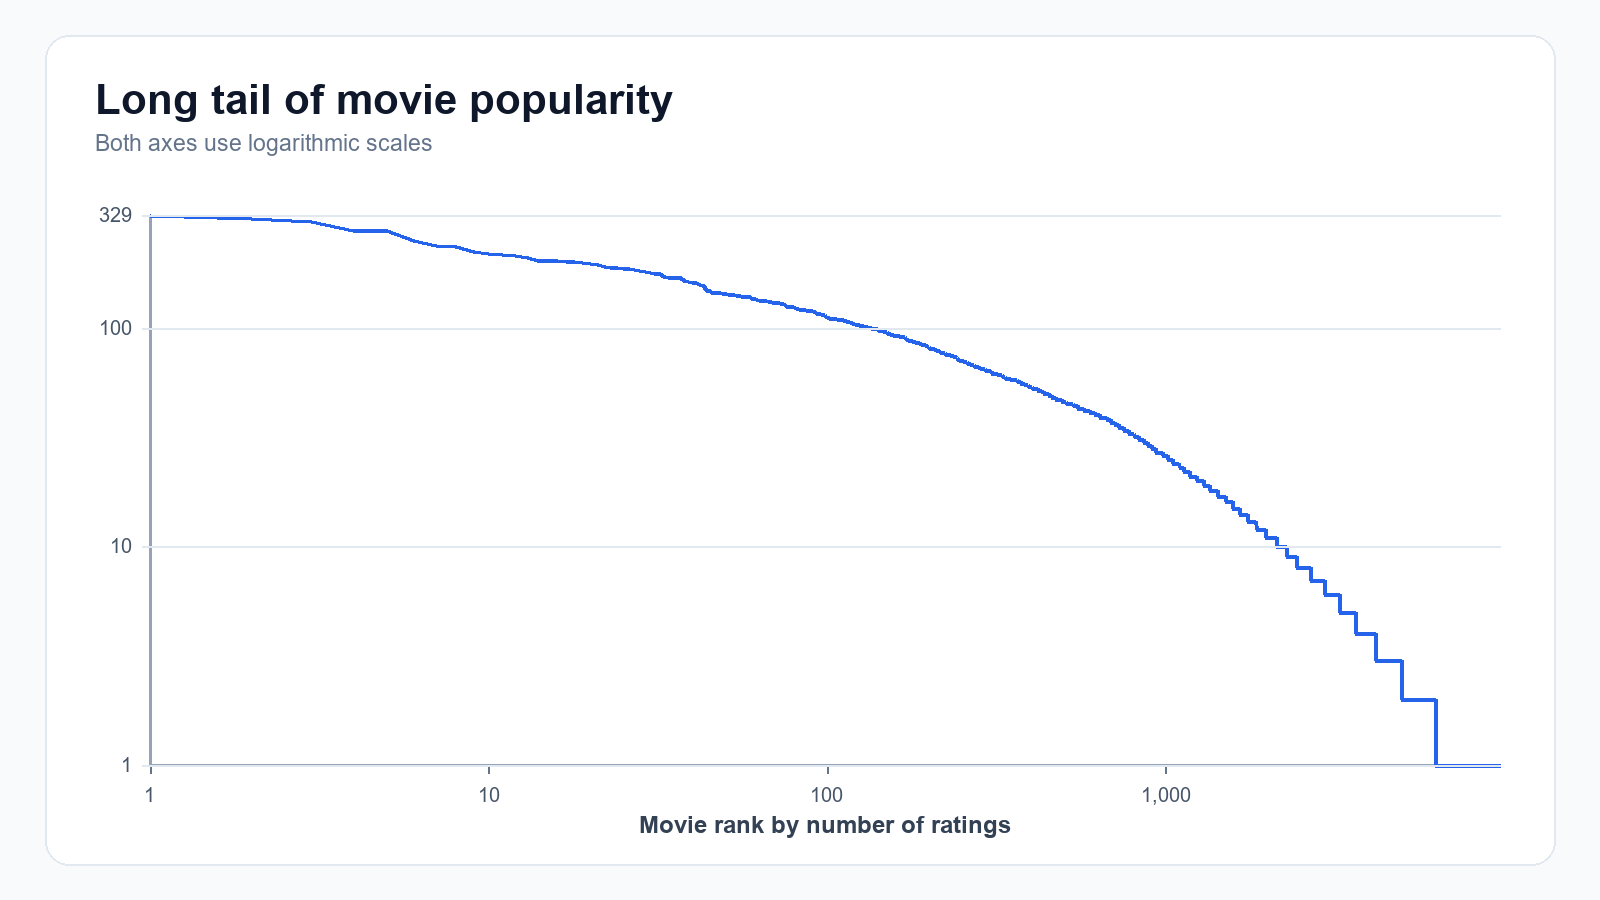

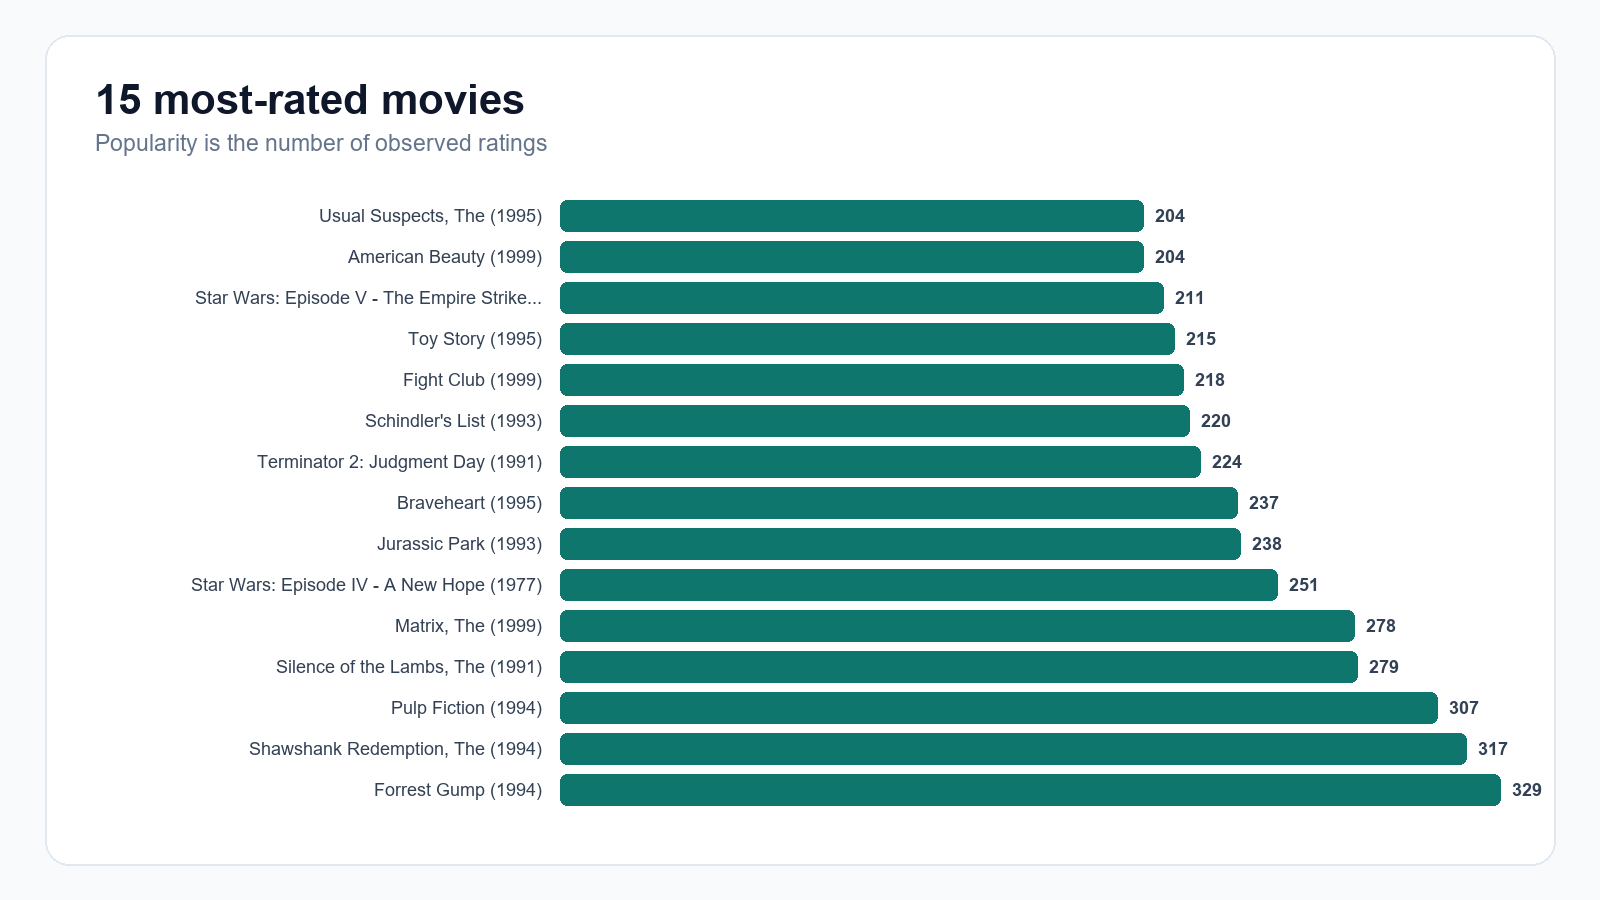

In [ ]:
display(Image(filename=ROOT / 'reports' / 'figures' / 'rating_distribution.png'))
display(Image(filename=ROOT / 'reports' / 'figures' / 'long_tail_distribution.png'))
display(Image(filename=ROOT / 'reports' / 'figures' / 'top_15_most_rated.png'))

## 4. Evidence-based observations
Use the computed summary and charts above when writing conclusions. Do not assume that the matrix is 99% empty or that users mostly choose a particular score; report the measured values from this snapshot.